## 0. 준비

아래 두 셀은 그대로 실행합니다. 실행하기 전에 프로젝트 폴더에 `.env` 파일이 있어야 합니다(`.env.example`을 복사해 비밀번호 입력).

In [8]:
# ===== 강사 제공 코드: 그대로 복사해서 사용합니다 =====
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv()
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PG_USER", "postgres"), password=os.getenv("PG_PASSWORD") or None,
    host=os.getenv("PG_HOST", "localhost"), port=int(os.getenv("PG_PORT", "5432")),
    database=os.getenv("PG_DB", "postgres"),
))

def q(sql, **params):        # SELECT 문을 실행하고 결과를 DataFrame으로 돌려줍니다
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

def q_file(name):            # ../sql 폴더의 SQL 파일을 읽어 실행합니다
    return q(Path("../sql", name).read_text(encoding="utf-8"))
# ===== 강사 제공 코드 끝 =====

In [9]:
def run(sql, params=None):   # INSERT / UPDATE / ALTER 등을 실행하고 COMMIT합니다
    with engine.begin() as conn:
        conn.execute(text(sql), params or {})

In [10]:
# 한글 글꼴 (Windows: Malgun Gothic / macOS: AppleGothic)
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

q("SELECT line_code, line_name, plan_per_shift FROM line_master")

,line_code,line_name,plan_per_shift
0,L1,냉장고 조립라인,400
1,L2,세탁기 조립라인,450
2,L3,에어컨 조립라인,350


위 셀에서 라인 3개가 표로 나오면 연결이 된 것입니다. **여기부터는 직접 작성합니다.**

## 미션 1. 상2

> "설비고장 나기 전에 온도나 진동에 이상 신호가 있었는지 확인해봐." 

**1. 지시 해석** — 무엇을 보고해야 하는지 한 줄로: 설비 고장 전 시기, 온도, 진동 등의 로그 데이터 시각화
고장남 - 고장 전, 온도, 진동 로그 추출, 고장 시기 


**2. 설계** — 필요한 테이블 · 컬럼 · 계산식: 
- 테이블: 온도- sensor_hourly-temp_c / 진동- sensor_hourly-vibration_mm_s / 설비 정보-equipment_master / 시기-sensor_hourly-measured_at / 고장 설비 및 시기-production_result
- 계산식: 불량률(defect_qty/prod_qty), 고장 시점을 기준으로 기간을 나눔()

In [11]:
# 실습 중 따로 만든 equip_judgment 테이블이 equipment_master를 참조하고 있어서,
# 이 테이블을 먼저 지워야 SQL 파일의 DROP TABLE equipment_master가 성공합니다
run("drop table if exists equip_judgment")

sql_file = Path("../../14. 생산DB_Python연동.sql")
script = sql_file.read_text(encoding="utf-8")

conn = engine.raw_connection()     # 여러 문장이 들어 있는 SQL 파일을 통째로 실행
try:
    cur = conn.cursor()
    cur.execute(script)
    conn.commit()
finally:
    conn.close()

q("""
    select 'production_result' as 테이블, count(*) as 행수 from production_result
    union all select 'sensor_hourly', count(*) from sensor_hourly
    union all select 'downtime_log',  count(*) from downtime_log
    union all select 'quality_judgment', count(*) from quality_judgment
""")


,테이블,행수
0,production_result,162
1,sensor_hourly,5832
2,downtime_log,203
3,quality_judgment,0


In [13]:
# 5. 검산: 합계·건수를 다른 방법으로 한 번 더 확인합니다
q("SELECT COUNT(*)" \
    "FROM production_result" )



,count
0,162


In [14]:
q("SELECT COUNT(*)" \
    "FROM equipment_master" )

,count
0,9


In [15]:
q("SELECT COUNT(*)" \
    "FROM sensor_hourly" )

,count
0,5832


In [16]:
shift_rate = q("""
    select result_id, work_date, shift, line_code, prod_qty, defect_qty,
           defect_qty * 1.0 / nullif(prod_qty, 0) as 불량률
    from production_result
""")
shift_rate['불량률'] = shift_rate['불량률'].astype(float).round(4)

tol2 = round(shift_rate['불량률'].mean() + 2 * shift_rate['불량률'].std(), 4)
tol3 = round(shift_rate['불량률'].mean() + 3 * shift_rate['불량률'].std(), 4)
print('k=2 임계치:', tol2, '/ k=3 임계치:', tol3)

shift_rate[shift_rate['불량률'] > tol2]


k=2 임계치: 0.0296 / k=3 임계치: 0.0367


,result_id,work_date,shift,line_code,prod_qty,defect_qty,불량률
70,71,2026-10-14,야간,L2,424,15,0.0354
76,77,2026-10-15,야간,L2,440,20,0.0455
79,80,2026-10-16,주간,L2,419,21,0.0501
82,83,2026-10-16,야간,L2,411,24,0.0584


In [17]:
run("""
    alter table quality_judgment
      add column equip_code   varchar(10) references equipment_master(equip_code),
      add column avg_vib      numeric(5,2),
      add column max_vib      numeric(5,2),
      add column avg_temp     numeric(5,1),
      add column max_temp     numeric(5,1),
      add column judge_reason varchar(50)
""")
run("alter table quality_judgment drop constraint quality_judgment_work_date_line_code_key")
run("alter table quality_judgment add constraint uq_qj_date_equip unique (work_date, equip_code)")


In [18]:
insert_sql = text("""
INSERT INTO quality_judgment (work_date, line_code, defect_rate, judgment)
VALUES (:work_date, :line_code, :defect_rate, :judgment)
""")

with engine.begin() as conn:   # 블록이 끝나면 COMMIT, 중간에 오류가 나면 ROLLBACK
    conn.execute(insert_sql, {"work_date": "2026-10-01", "line_code": "L1",
                              "defect_rate": 1.53, "judgment": "정상"})

q("SELECT work_date, line_code, defect_rate, judgment FROM quality_judgment")

,work_date,line_code,defect_rate,judgment
0,2026-10-01,L1,1.53,정상


In [19]:
# 불량률 구하기 -> 불량개수 / 생산 개수

q("select result_id, prod_qty, defect_qty, work_date, "
  " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
  " from production_result ")


,result_id,prod_qty,defect_qty,work_date,불량률
0,1,364,5,2026-10-01,0.0137
1,2,417,4,2026-10-01,0.0096
2,3,320,2,2026-10-01,0.0063
3,4,353,6,2026-10-01,0.0170
4,5,441,7,2026-10-01,0.0159
...,...,...,...,...,...
157,158,410,6,2026-10-31,0.0146
158,159,307,3,2026-10-31,0.0098
159,160,380,5,2026-10-31,0.0132
160,161,449,11,2026-10-31,0.0245


In [20]:
# 0.015 불량률 임계치 넘는 결과 값 출력

q("select result_id, prod_qty, defect_qty, work_date, "
  " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
  " from production_result " \
  " where round(defect_qty::numeric / nullif(prod_qty, 0), 4) > 0.015" \
  " order by 불량률")

,result_id,prod_qty,defect_qty,work_date,불량률
0,72,331,5,2026-10-14,0.0151
1,84,332,5,2026-10-16,0.0151
2,113,394,6,2026-10-22,0.0152
3,27,330,5,2026-10-06,0.0152
4,131,391,6,2026-10-26,0.0153
...,...,...,...,...,...
71,74,442,12,2026-10-15,0.0271
72,71,424,15,2026-10-14,0.0354
73,77,440,20,2026-10-15,0.0455
74,80,419,21,2026-10-16,0.0501


In [21]:
# 불량률 임계치 구하기 : 평균 + k × 표준편차

defect_avg, defect_std = q("select avg(불량률), stddev(불량률) " \
    "from (" \
    "select result_id, "
    " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
    " from production_result ) t"
    ).iloc[0].astype(float)

In [22]:
# k=2 임계치 구하기
tol2 = round(defect_avg + 2 * defect_std, 4)

# k=3 임계치 구하기
tol3 = round(defect_avg + 3 * defect_std, 4)

print(tol2, tol3)

0.0296 0.0367


In [23]:
# tol2 기준으로 불량 설비 추출
q("select result_id, prod_qty, defect_qty, work_date, "
  " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
  " from production_result " \
  " where round(defect_qty::numeric / nullif(prod_qty, 0), 4) > :tol", tol= tol2 \
  )

,result_id,prod_qty,defect_qty,work_date,불량률
0,71,424,15,2026-10-14,0.0354
1,77,440,20,2026-10-15,0.0455
2,80,419,21,2026-10-16,0.0501
3,83,411,24,2026-10-16,0.0584


In [25]:
import numpy as np

# 1) 설비·일자별 온도·진동
sensor = q("""
    select s.measured_at::date as work_date,
           s.equip_code,
           e.line_code,
           avg(s.vibration_mm_s) as avg_vib,
           max(s.vibration_mm_s) as max_vib,
           avg(s.temp_c)         as avg_temp,
           max(s.temp_c)         as max_temp
    from sensor_hourly s
    join equipment_master e on s.equip_code = e.equip_code
    group by s.measured_at::date, s.equip_code, e.line_code
""")

# 2) 일자·라인별 불량률 (%)
rate = q("""
    select work_date,
           line_code,
           sum(defect_qty) * 100.0 / nullif(sum(prod_qty), 0) as defect_rate
    from production_result
    group by work_date, line_code
""")
rate['defect_rate'] = rate['defect_rate'].astype(float).round(2)

# 3) 라인별 임계치 = 평균 + 2σ
K = 2
limit = rate.groupby('line_code')['defect_rate'].agg(['mean', 'std']).reset_index()
limit['limit_rate'] = (limit['mean'] + K * limit['std']).round(2)
rate = rate.merge(limit[['line_code', 'limit_rate']], on='line_code')

rate['judgment'] = np.where(rate['defect_rate'] > rate['limit_rate'], '이상', '정상')
rate['judge_reason'] = np.where(
    rate['judgment'] == '이상',
    '불량률 ' + rate['defect_rate'].astype(str) + '% > 기준 ' + rate['limit_rate'].astype(str) + '%',
    None)

# 4) 설비 행에 라인 판정을 붙여서 합치기
df = sensor.merge(rate, on=['work_date', 'line_code'])
num = ['avg_vib', 'max_vib', 'avg_temp', 'max_temp']
df[num] = df[num].astype(float).round(2)

# 5) 한 번에 INSERT
cols = ['work_date', 'line_code', 'equip_code', 'defect_rate',
        'avg_vib', 'max_vib', 'avg_temp', 'max_temp', 'judgment', 'judge_reason']
rows = df[cols].astype(object).where(df[cols].notna(), None).to_dict('records')   # NaN → NULL

with engine.begin() as conn:
    conn.execute(text("""
        insert into quality_judgment
          (work_date, line_code, equip_code, defect_rate, avg_vib, max_vib, avg_temp, max_temp, judgment, judge_reason)
        values
          (:work_date, :line_code, :equip_code, :defect_rate, :avg_vib, :max_vib, :avg_temp, :max_temp, :judgment, :judge_reason)
    """), rows)

display(limit)
q("select line_code, judgment, count(distinct work_date) as 일수 from quality_judgment group by 1, 2 order by 1, 2")


,line_code,mean,std,limit_rate
0,L1,1.483704,0.197214,1.88
1,L2,1.940370,0.859165,3.66
2,L3,1.216296,0.218564,1.65


,line_code,judgment,일수
0,L1,이상,1
1,L1,정상,26
2,L2,이상,1
3,L2,정상,26
4,L3,정상,27


In [26]:
q("select * from quality_judgment")

,judge_id,work_date,line_code,defect_rate,judgment,judged_by,judged_at,equip_code,avg_vib,max_vib,avg_temp,max_temp,judge_reason
0,1,2026-10-01,L1,1.53,정상,python,2026-11-20 17:22:39.667792,None,NaN,NaN,NaN,NaN,None
1,2,2026-10-01,L3,0.92,정상,python,2026-11-20 17:23:54.418456,EQ-302,2.02,2.48,30.0,32.2,None
2,3,2026-10-10,L1,1.61,정상,python,2026-11-20 17:23:54.418456,EQ-103,2.04,2.55,28.2,30.8,None
3,4,2026-10-22,L1,1.70,정상,python,2026-11-20 17:23:54.418456,EQ-102,2.02,2.37,31.8,34.0,None
4,5,2026-10-08,L2,1.51,정상,python,2026-11-20 17:23:54.418456,EQ-202,1.92,2.41,33.1,35.1,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,240,2026-10-23,L3,0.90,정상,python,2026-11-20 17:23:54.418456,EQ-302,1.95,2.35,29.9,32.3,None
240,241,2026-10-17,L1,1.29,정상,python,2026-11-20 17:23:54.418456,EQ-102,2.02,2.66,32.0,34.2,None
241,242,2026-10-21,L1,1.62,정상,python,2026-11-20 17:23:54.418456,EQ-103,2.05,2.56,28.0,29.8,None
242,243,2026-10-23,L2,1.60,정상,python,2026-11-20 17:23:54.418456,EQ-203,2.09,2.49,29.1,31.3,None


In [ ]:
# 그래프용 라이브러리 (아래 그래프 셀에서 mdates를 사용)
import matplotlib.dates as mdates

NameError: name 'mdates' is not defined

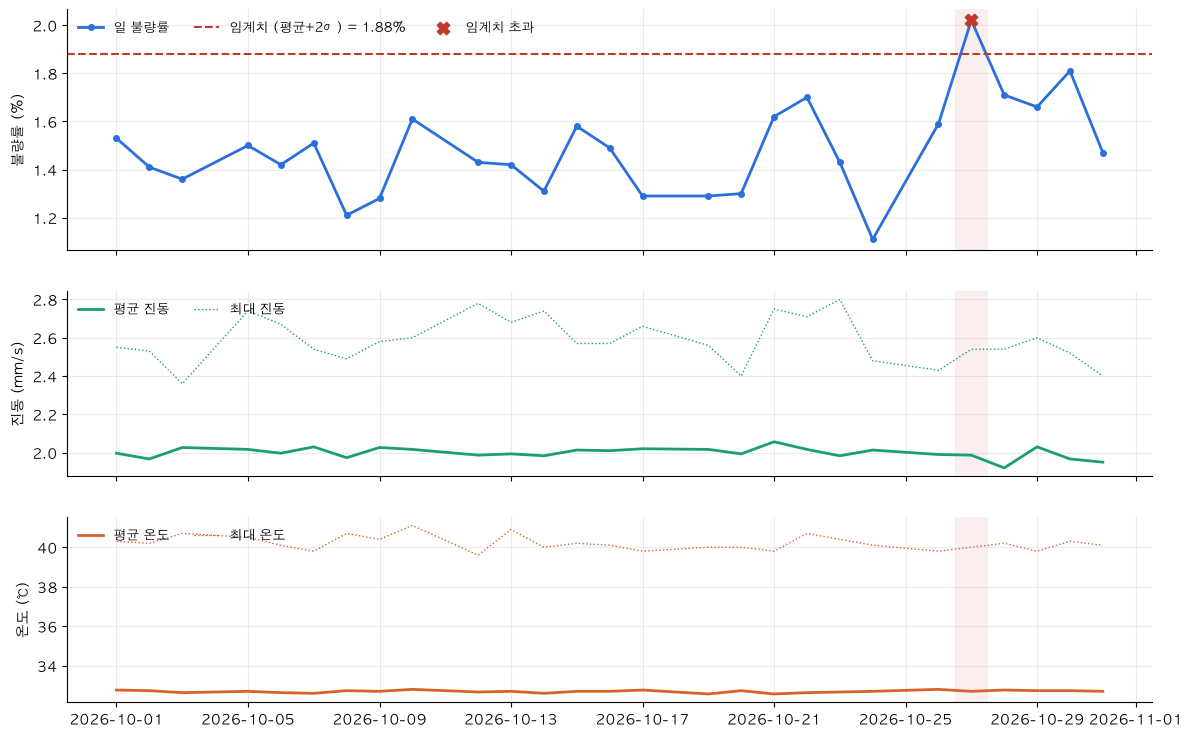

In [27]:
line_daily = q("""
    select work_date, line_code,
           max(defect_rate) as defect_rate,
           avg(avg_vib)  as avg_vib,  max(max_vib)  as max_vib,
           avg(avg_temp) as avg_temp, max(max_temp) as max_temp
    from quality_judgment
    group by work_date, line_code
    order by line_code, work_date
""")
num = ['defect_rate', 'avg_vib', 'max_vib', 'avg_temp', 'max_temp']
line_daily[num] = line_daily[num].astype(float)
line_daily['work_date'] = pd.to_datetime(line_daily['work_date'])

C_RATE, C_VIB, C_TEMP, C_LIMIT = '#2a6fdb', '#1a9e77', '#d9622b', '#c0392b'

def plot_line_trend(line_code):
    d = line_daily[line_daily['line_code'] == line_code]
    lim = d['defect_rate'].mean() + K * d['defect_rate'].std()
    over = d[d['defect_rate'] > lim]

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 9), sharex=True,
                                        gridspec_kw={'height_ratios': [1.3, 1, 1]})
    ax1.plot(d['work_date'], d['defect_rate'], color=C_RATE, lw=2, marker='o', ms=4, label='일 불량률')
    ax1.axhline(lim, color=C_LIMIT, ls='--', lw=1.5, label=f'임계치 (평균+{K}σ) = {lim:.2f}%')
    ax1.scatter(over['work_date'], over['defect_rate'], color=C_LIMIT, marker='X', s=80, zorder=3, label='임계치 초과')
    ax1.set_ylabel('불량률 (%)')

    ax2.plot(d['work_date'], d['avg_vib'], color=C_VIB, lw=2, label='평균 진동')
    ax2.plot(d['work_date'], d['max_vib'], color=C_VIB, lw=1, ls=':', label='최대 진동')
    ax2.set_ylabel('진동 (mm/s)')

    ax3.plot(d['work_date'], d['avg_temp'], color=C_TEMP, lw=2, label='평균 온도')
    ax3.plot(d['work_date'], d['max_temp'], color=C_TEMP, lw=1, ls=':', label='최대 온도')
    ax3.set_ylabel('온도 (℃)')

    for ax in (ax1, ax2, ax3):
        for day in over['work_date']:
            ax.axvspan(day - pd.Timedelta(hours=12), day + pd.Timedelta(hours=12), color=C_LIMIT, alpha=0.08, lw=0)
        ax.legend(loc='upper left', frameon=False, ncol=3, fontsize=9)
        ax.grid(alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)

    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
    fig.suptitle(f'{line_code} 라인 — 일자별 불량률과 같은 시기의 진동·온도 (임계치 초과 {len(over)}일)',
                 x=0.01, ha='left', fontsize=14)
    fig.tight_layout()
    fig.savefig(f'../images/상2_{line_code}_불량률_진동온도.png', dpi=150, bbox_inches='tight')
    plt.show()

for line in ['L1', 'L2', 'L3']:
    plot_line_trend(line)


### 더 잘게 보기 ① L2 교대별 불량률

In [ ]:
l2_shift = shift_rate[(shift_rate['line_code'] == 'L2') &
                      (shift_rate['work_date'].astype(str).between('2026-10-13', '2026-10-17'))]

table = l2_shift.pivot(index='work_date', columns='shift', values='불량률')[['주간', '야간']] * 100
print('교대 임계치(k=2):', round(tol2 * 100, 2), '%')
table.round(2)

### 더 잘게 보기 ② EQ-201 시각별 온도·진동 + 실제 고장 기록

In [ ]:
hourly = q("""
    select measured_at, temp_c, vibration_mm_s
    from sensor_hourly
    where equip_code = 'EQ-201'
    order by measured_at
""")
hourly[['temp_c', 'vibration_mm_s']] = hourly[['temp_c', 'vibration_mm_s']].astype(float)

# 평소 값: 이상 구간(10/12 ~ 10/20)을 뺀 기간
day = hourly['measured_at'].dt.strftime('%Y-%m-%d')
normal = hourly[(day < '2026-10-12') | (day > '2026-10-20')]

result = []
for col, name in [('temp_c', '온도'), ('vibration_mm_s', '진동')]:
    m, s = normal[col].mean(), normal[col].std()
    lim = m + 3 * s
    first = hourly[(hourly[col] > lim) & (day.between('2026-10-10', '2026-10-17'))]['measured_at'].min()
    result.append({'신호': name, '평소 평균': round(m, 2), '기준(평균+3σ)': round(lim, 2), '처음 넘은 시각': first})
display(pd.DataFrame(result))

# 실제 고장 기록
q("""
    select start_time, end_time, duration_min, reason
    from downtime_log
    where equip_code = 'EQ-201'
      and work_date between '2026-10-13' and '2026-10-18'
    order by start_time
""")

**7. 보고**: (결론 1문장 + 근거 수치 — 확인하지 못한 원인은 「추가 확인 필요」)

---
## AI 질문 로그

AI에게 한 질문을 그때그때 적습니다. 질문을 하지 않았다면 「질문 없음」이라고 적습니다.

| 시각 | 질문 요지 | 알게 된 것 | 내 코드에 어떻게 적용했는지 |
| --- | --- | --- | --- |
|  |  |  |  |
|  |  |  |  |